# Sales Simulation and Order Volume

**Question.** Does printing 30 newspapers per week improve profit compared with printing 20? Separately, how do order volume and time to shipment vary in the fictional Superstore?

The newspaper example uses a 100-week frequency table from coursework. The retail analysis uses a public version of [Tableau’s sample workbook](https://public.tableau.com/app/resources/sample-data).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
data_dir = Path("../data") if Path("../data").is_dir() else Path("data")

## 1. Simulate a shared demand distribution

Each draw represents one week. Both print quantities face the same draws. Each copy sells for $0.50, costs $0.30 to print, and has zero salvage value.

,Mean units sold,Mean unsold units,Mean revenue ($),Mean profit ($),Weeks with unmet demand (%)
Copies printed,,,,,
20,18.49,1.51,9.25,3.25,27.83
30,19.04,10.96,9.52,0.52,0.00


Print 20 copies under these assumptions. Mean weekly profit is $2.73 higher.


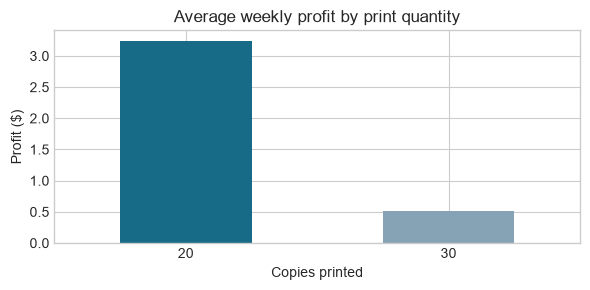

In [2]:
demand_values = np.arange(13, 27)
week_counts = np.array([1, 2, 4, 9, 10, 15, 16, 15, 12, 9, 4, 2, 1, 0])
assert week_counts.sum() == 100
probabilities = week_counts / week_counts.sum()

rng = np.random.default_rng(42)
weekly_demand = rng.choice(demand_values, size=20_000, p=probabilities)
unit_price, unit_cost = 0.50, 0.30
scenario_rows = []

for copies in (20, 30):
    sold = np.minimum(weekly_demand, copies)
    revenue = sold * unit_price
    profit = revenue - copies * unit_cost
    scenario_rows.append({
        "Copies printed": copies,
        "Mean units sold": sold.mean(),
        "Mean unsold units": (copies - sold).mean(),
        "Mean revenue ($)": revenue.mean(),
        "Mean profit ($)": profit.mean(),
        "Weeks with unmet demand (%)": 100 * (weekly_demand > copies).mean(),
    })

scenarios = pd.DataFrame(scenario_rows).set_index("Copies printed")
display(scenarios.round(2))
winner = scenarios["Mean profit ($)"].idxmax()
profit_gap = scenarios["Mean profit ($)"].max() - scenarios["Mean profit ($)"].min()
print(f"Print {winner} copies under these assumptions. Mean weekly profit is ${profit_gap:.2f} higher.")

ax = scenarios["Mean profit ($)"].plot.bar(color=["#176B87", "#86A3B5"], rot=0, figsize=(6, 3))
ax.set(title="Average weekly profit by print quantity", ylabel="Profit ($)")
plt.tight_layout()
plt.show()

## 2. Track volume and time to shipment

Aggregate line-item quantities by order date. Include zero-order dates within the observed range, then plot a trailing 28-day average. For time to shipment, count each order once using the last shipment date across its lines.

D:\Work\Job\Data Paractice\data-science-portfolio\.venv\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


5,009 orders from 2015-01-03 to 2018-12-30
Median time to final shipment: 4 days
90th percentile time to final shipment: 6 days


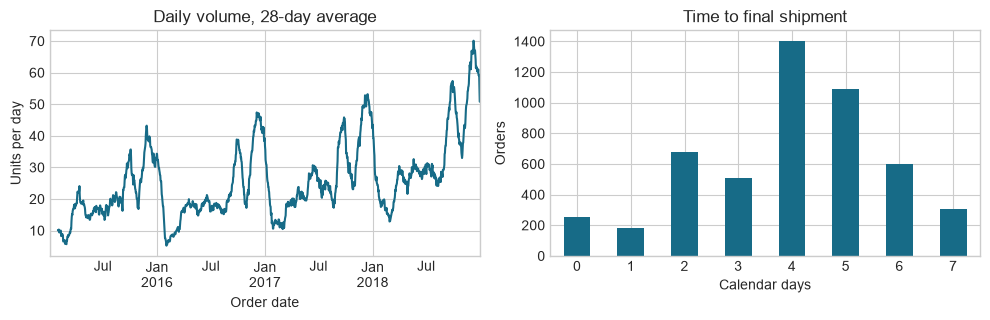

In [3]:
orders = pd.read_excel(
    data_dir / "superstore.xlsx",
    sheet_name="Orders",
    usecols=["Order ID", "Order Date", "Ship Date", "Quantity"],
)
orders["Order Date"] = pd.to_datetime(orders["Order Date"])
orders["Ship Date"] = pd.to_datetime(orders["Ship Date"])
assert not orders.isna().any().any()
assert (orders["Ship Date"] >= orders["Order Date"]).all()
assert (orders["Quantity"] > 0).all()

daily_units = orders.groupby("Order Date")["Quantity"].sum().asfreq("D", fill_value=0)
order_ship_dates = orders.groupby("Order ID").agg(
    ordered=("Order Date", "min"), fully_shipped=("Ship Date", "max")
)
ship_days = (order_ship_dates["fully_shipped"] - order_ship_dates["ordered"]).dt.days

print(f"{len(order_ship_dates):,} orders from {daily_units.index.min():%Y-%m-%d} to {daily_units.index.max():%Y-%m-%d}")
print(f"Median time to final shipment: {ship_days.median():.0f} days")
print(f"90th percentile time to final shipment: {ship_days.quantile(.9):.0f} days")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
daily_units.rolling(28).mean().plot(ax=axes[0], color="#176B87")
axes[0].set(title="Daily volume, 28-day average", xlabel="Order date", ylabel="Units per day")
ship_days.value_counts().sort_index().plot.bar(ax=axes[1], color="#176B87", rot=0)
axes[1].set(title="Time to final shipment", xlabel="Calendar days", ylabel="Orders")
fig.tight_layout()
plt.show()

Higher print volume can reduce missed demand while increasing waste and cost. The simulation compares two fixed quantities at one price. The Superstore charts summarize activity between the first and last observed order dates.